In [7]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "textstyle").is_dir())
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Image, display
from sklearn.metrics import auc, roc_curve

from textstyle.data import load_splits, read_corpus, verify_splits
from textstyle.evaluation import collect_logits, metrics_from_logits
from textstyle.models import build_model
from textstyle.predict import Predictor
from textstyle.settings import STYLES, TONES
from textstyle.tokenization import Collator, TextDataset, Vocabulary, tokenize
from textstyle.train import make_loader, train_experiment

torch.set_num_threads(2)
print("Python:", sys.version.split()[0], "PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

%matplotlib inline

Python: 3.12.10 PyTorch: 2.8.0+cpu
CUDA: False


## Навчання і вибір моделі

Для комплектних CNN і BiLSTM виконано до 35 епох на CPU з patience 7. Для DistilBERT виконано 4 епохи донавчання. Перемагає середній macro F1 двох задач на validation. Температурне калібрування також використовує тільки validation. Тестові мітки не використовуються у loss, побудові словника, виборі checkpoint чи температури.

Наступна клітинка за замовчуванням завантажує реальні збережені результати. Прапорець RUN_TRAINING запускає новий експеримент у experiments/notebook_run і потребує часу. Для точного повторення трансформера додатково запустіть команду з README.

In [8]:
RUN_TRAINING = False
if RUN_TRAINING:
    experiment = train_experiment(
        architectures=["cnn", "bilstm"],
        data_dir=ROOT / "data/prepared",
        output=ROOT / "experiments/notebook_run",
        epochs=35,
        patience=7,
        seed=42,
        device="cpu",
    )
else:
    experiment = json.loads((ROOT / "artifacts/experiment.json").read_text())
print("Модель, обрана за validation:", experiment["selected_model"])
display(
    pd.DataFrame(
        [
            {
                "model": name,
                "validation_mean_macro_f1": run["validation_mean_macro_f1"],
                "best_epoch": run["best_epoch"],
                "training_seconds": round(run["training_seconds"], 1),
            }
            for name, run in experiment["models"].items()
        ]
    )
)

Модель, обрана за validation: transformer


,model,validation_mean_macro_f1,best_epoch,training_seconds
0,cnn,0.883500,29,30.3
1,bilstm,0.805021,11,48.8
2,transformer,0.951825,3,748.8


CNN


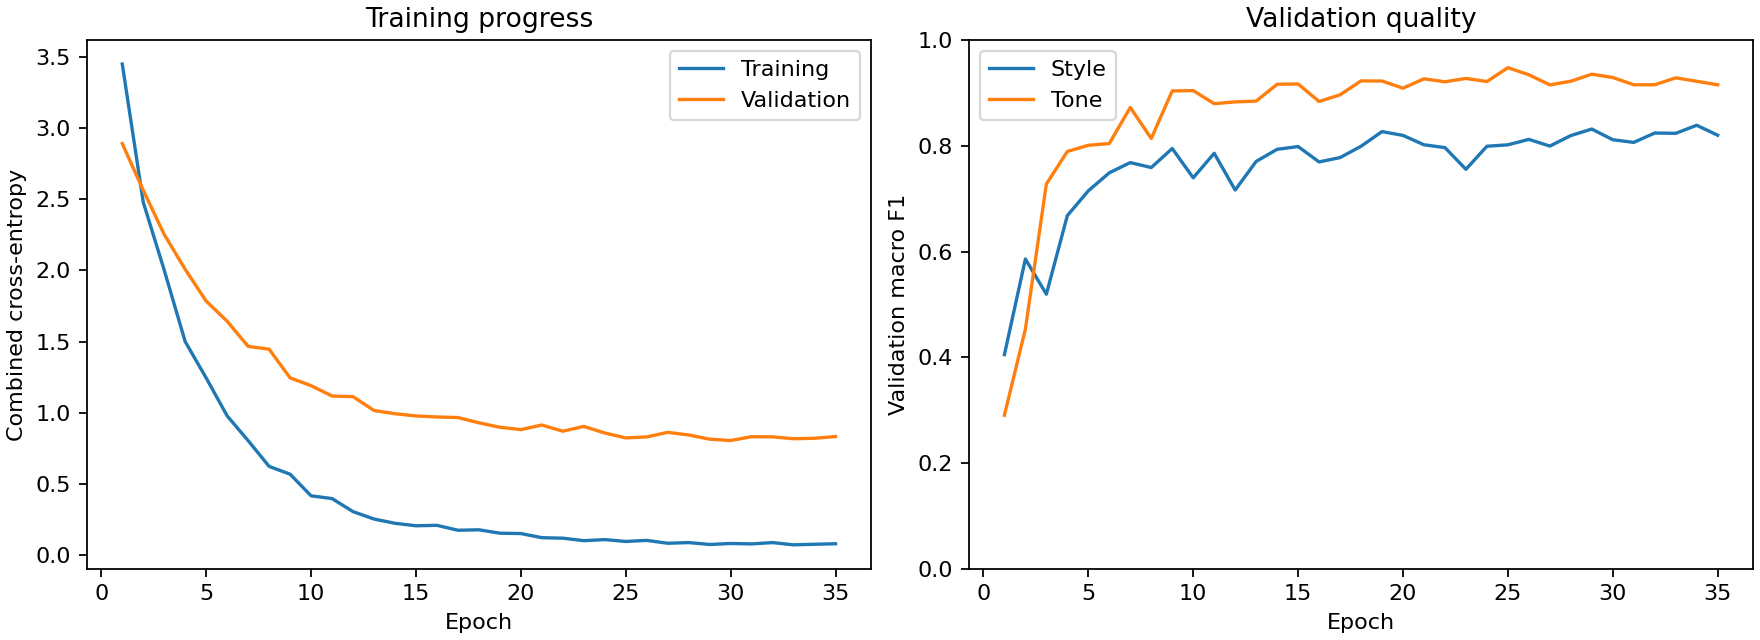

BILSTM


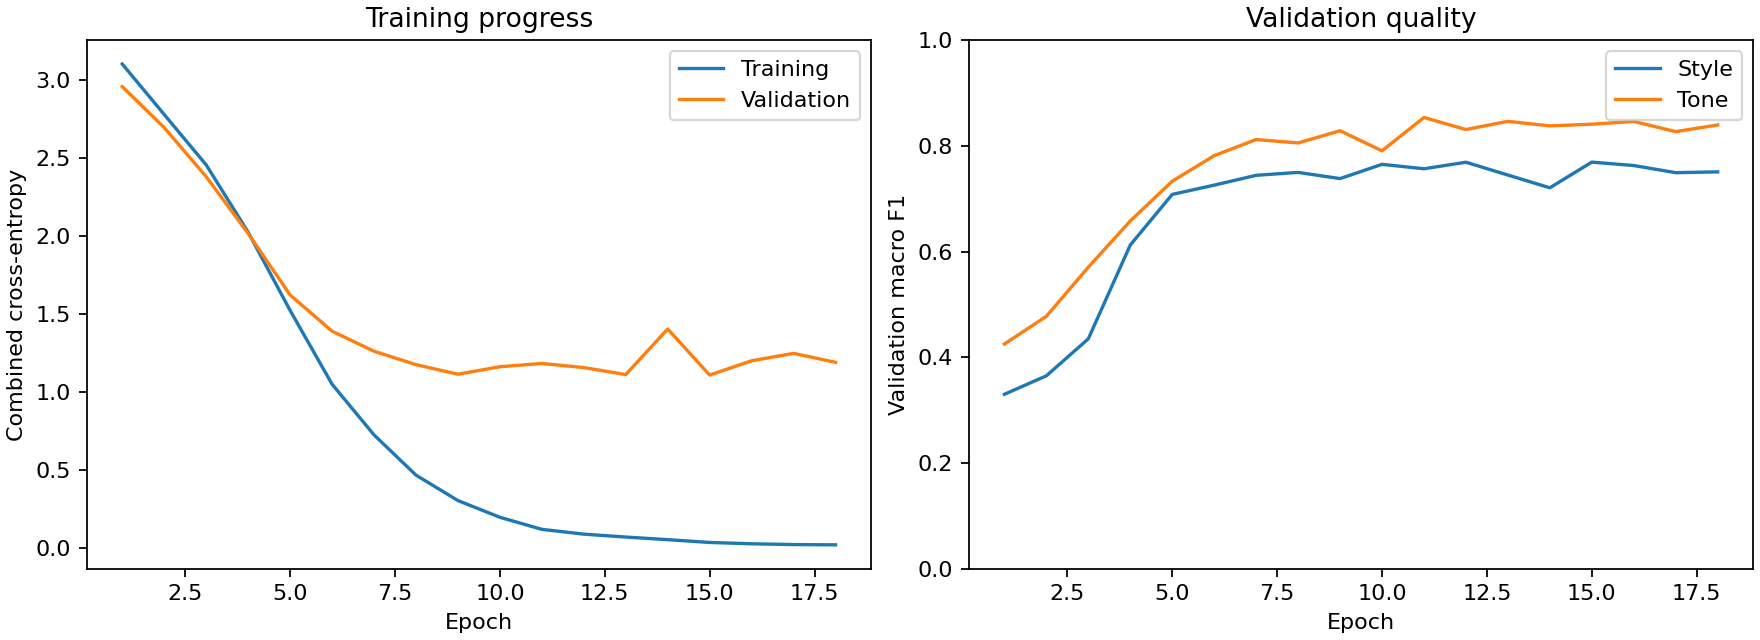

TRANSFORMER


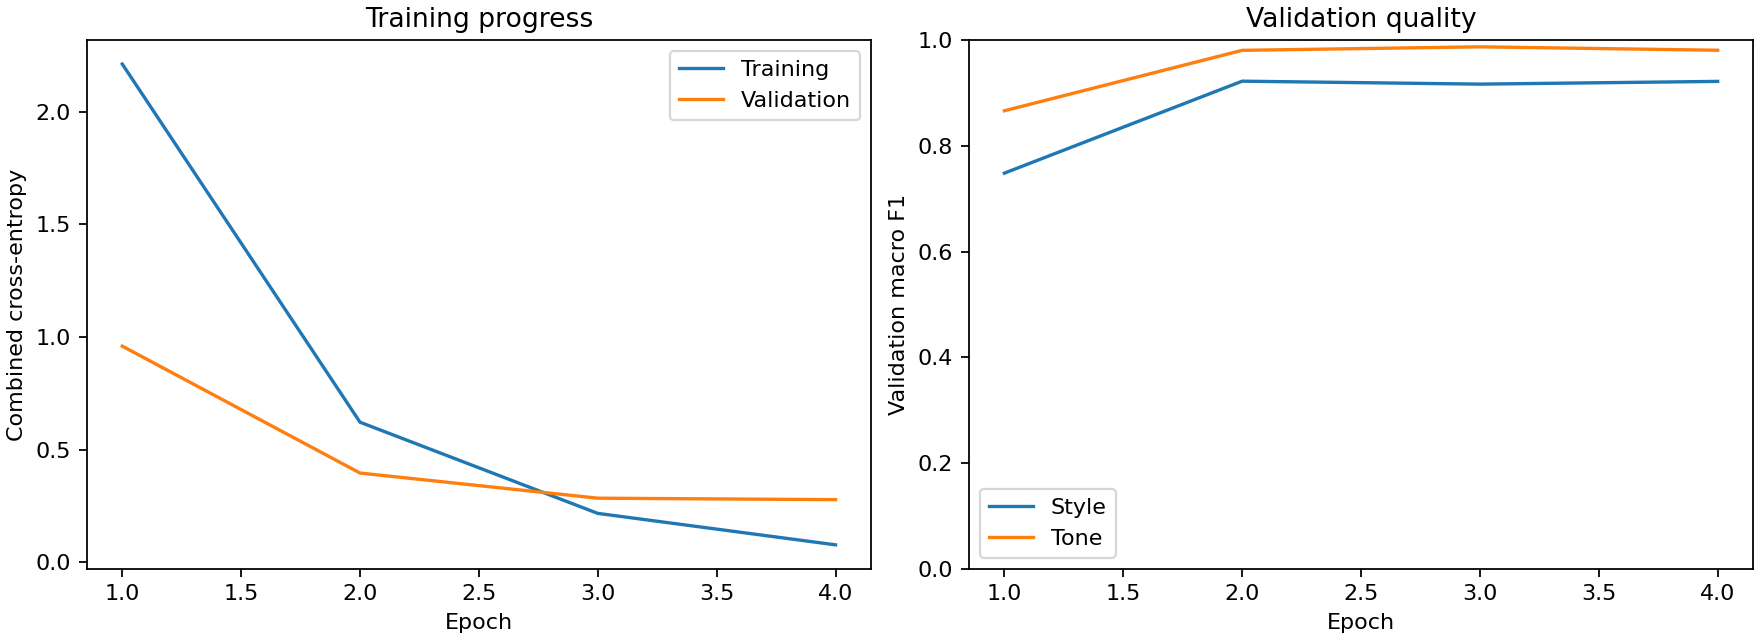

In [9]:
for name in experiment["models"]:
    print(name.upper())
    display(Image(filename=str(ROOT / f"artifacts/{name}/learning_curves.png"), width=950))

## Оцінювання на незалежній тестовій вибірці

Macro F1 однаково враховує всі п'ять класів. Accuracy показує частку правильних міток, а joint accuracy — частку текстів з одночасно правильним стилем і тоном. ROC-AUC обчислюємо за схемою one-vs-rest. Показники нижче стосуються 208 відкладених текстів цього корпусу та не є оцінкою зовнішньої виробничої якості.

,style_accuracy,style_macro_f1,tone_accuracy,tone_macro_f1,joint_accuracy
model,,,,,
cnn,0.8413,0.8402,0.8942,0.8927,0.7837
bilstm,0.7837,0.7816,0.8462,0.8420,0.6827
transformer,0.9327,0.9338,0.9712,0.9709,0.9038


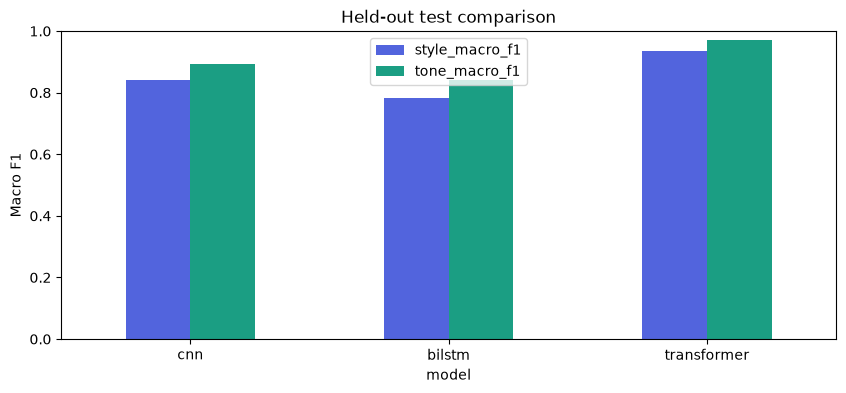

In [10]:
comparison = pd.DataFrame(
    [
        {
            "model": name,
            "style_accuracy": run["test"]["style"]["accuracy"],
            "style_macro_f1": run["test"]["style"]["f1_macro"],
            "tone_accuracy": run["test"]["tone"]["accuracy"],
            "tone_macro_f1": run["test"]["tone"]["f1_macro"],
            "joint_accuracy": run["test"]["joint_accuracy"],
        }
        for name, run in experiment["models"].items()
    ]
).set_index("model")
display(comparison.round(4))
ax = comparison[["style_macro_f1", "tone_macro_f1"]].plot.bar(figsize=(10, 4), color=["#5264dd", "#1b9e83"])
ax.set(ylim=(0, 1), ylabel="Macro F1", title="Held-out test comparison")
ax.tick_params(axis="x", rotation=0)
plt.show()

,precision,recall,f1-score,support
academic,0.950,0.950,0.950,40.000
business,0.898,0.898,0.898,49.000
formal,0.846,0.846,0.846,39.000
informal,0.976,1.000,0.988,40.000
literary,1.000,0.975,0.987,40.000
accuracy,0.933,0.933,0.933,0.933
macro avg,0.934,0.934,0.934,208.000
weighted avg,0.933,0.933,0.933,208.000


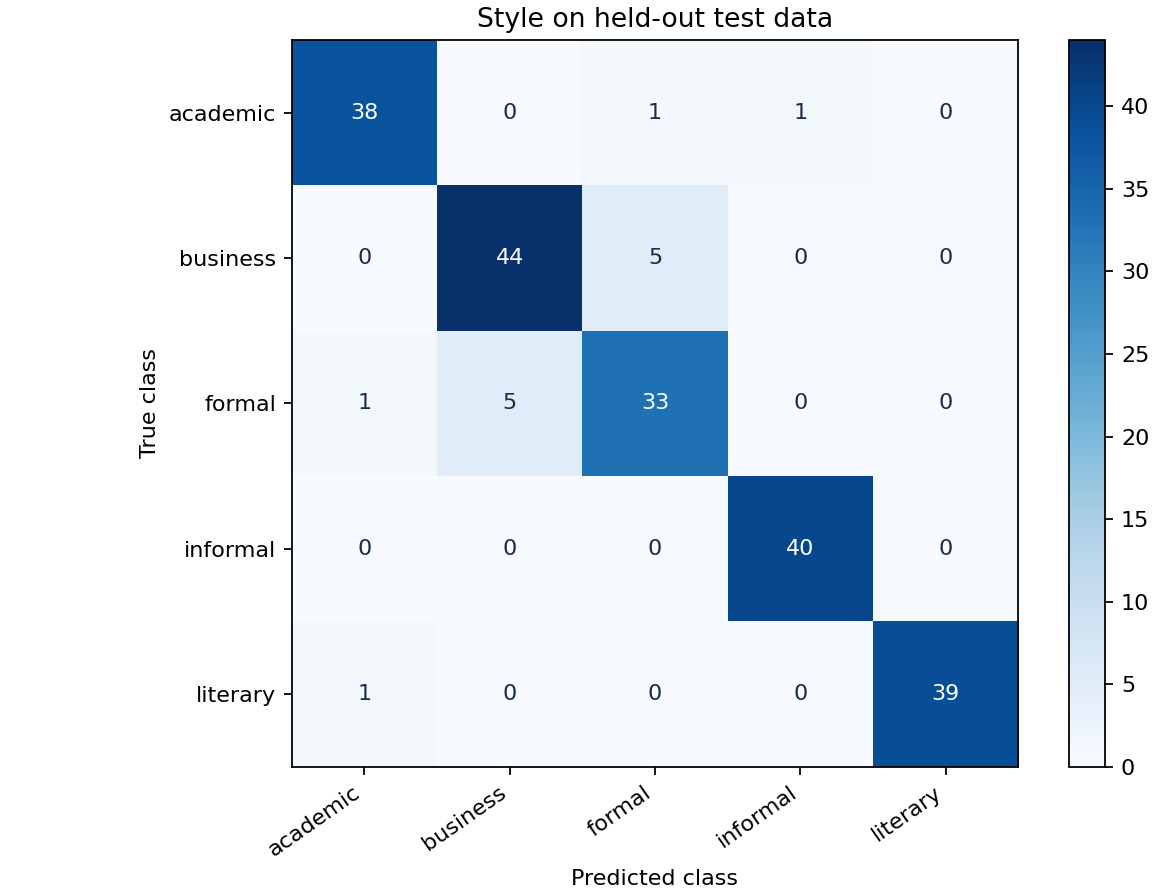

,precision,recall,f1-score,support
aggressive,1.000,0.950,0.974,40.000
friendly,0.951,0.975,0.963,40.000
neutral,0.975,0.975,0.975,40.000
sarcastic,0.951,0.975,0.963,40.000
urgent,0.979,0.979,0.979,48.000
accuracy,0.971,0.971,0.971,0.971
macro avg,0.971,0.971,0.971,208.000
weighted avg,0.972,0.971,0.971,208.000


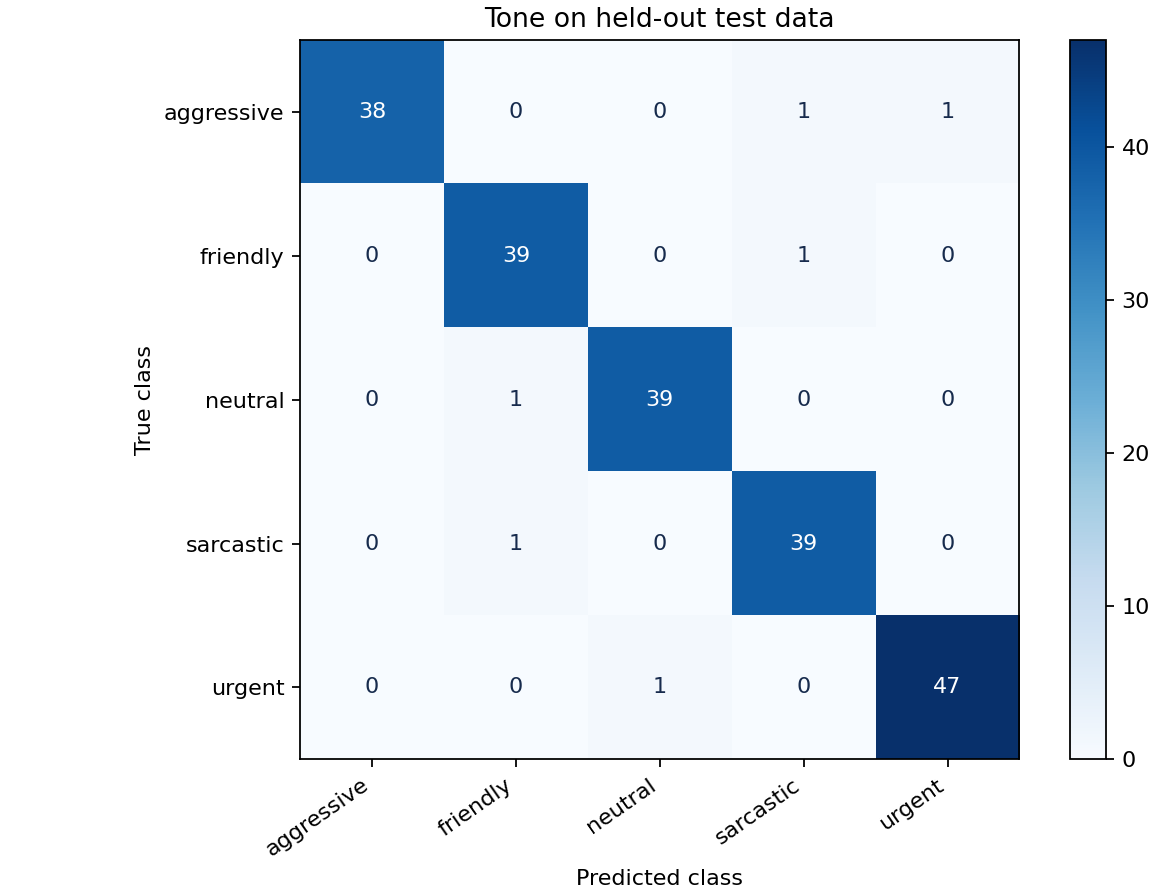

Повторне оцінювання збігається зі збереженим звітом.


In [11]:
frames, manifest = load_splits(ROOT / "data/prepared")
winner = experiment["selected_model"]
predictor = Predictor(ROOT / f"artifacts/{winner}/model")
test_loader = make_loader(frames["test"], predictor.tokenizer, 16)
collected = collect_logits(predictor.model, test_loader, predictor.device)
recomputed = metrics_from_logits(collected, predictor.metadata["temperatures"])
for target in ["style", "tone"]:
    assert abs(recomputed[target]["f1_macro"] - experiment["models"][winner]["test"][target]["f1_macro"]) < 1e-8
    display(pd.DataFrame(recomputed[target]["classification_report"]).T.round(3))
    display(Image(filename=str(ROOT / f"artifacts/{winner}/test/{target}_confusion.png"), width=650))
print("Повторне оцінювання збігається зі збереженим звітом.")

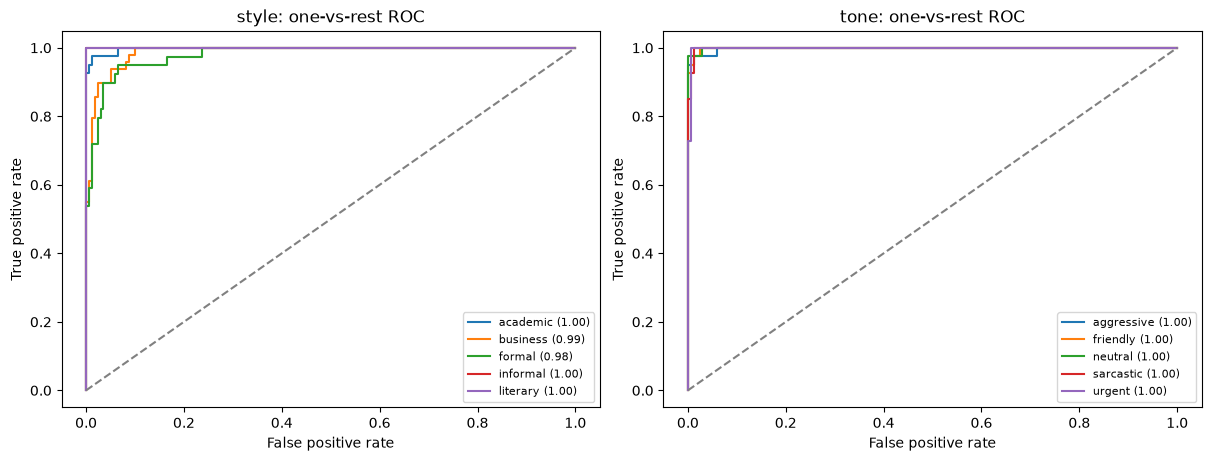

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, target, names in zip(axes, ["style", "tone"], [STYLES, TONES], strict=True):
    labels = collected[f"{target}_labels"].numpy()
    probabilities = (collected[f"{target}_logits"] / predictor.metadata["temperatures"][target]).softmax(-1).numpy()
    for i, name in enumerate(names):
        fpr, tpr, _ = roc_curve(labels == i, probabilities[:, i])
        ax.plot(fpr, tpr, label=f"{name} ({auc(fpr, tpr):.2f})")
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title=f"{target}: one-vs-rest ROC")
    ax.legend(fontsize=8)
plt.show()

## Аналіз помилок та перевірка нових текстів

Порівнюємо фактичні та передбачені мітки. Особливу увагу приділяємо перетину formal/business, коротким повідомленням і сарказму без контексту. Приклади нижче призначені для демонстрації й не мають незалежної еталонної розмітки.

In [13]:
errors = pd.read_csv(ROOT / f"artifacts/{winner}/test/errors.csv")
print("Тестові тексти з хоча б однією помилкою:", len(errors))
display(errors[["text", "style", "predicted_style", "tone", "predicted_tone"]].head(10))
examples = [
    "Dear team, please send your revised budget before the meeting today.",
    "Hey friend, thank you so much for your help!",
    "Wonderful, another pointless meeting. Exactly what I needed.",
]
predictions = predictor.predict_batch(examples)
display(
    pd.DataFrame(
        [
            {
                "text": text,
                "style": prediction["style"],
                "tone": prediction["tone"],
                "style_score": prediction["style_confidence"],
                "tone_score": prediction["tone_confidence"],
            }
            for text, prediction in zip(examples, predictions, strict=True)
        ]
    )
)

Тестові тексти з хоча б однією помилкою: 20


,text,style,predicted_style,tone,predicted_tone
0,The board of directors has approved the strate...,business,formal,neutral,neutral
1,Thank you for your recent submission of the re...,business,formal,neutral,neutral
2,The result is clear.,academic,formal,neutral,neutral
3,"Your methodology is entirely unscientific, try...",academic,academic,aggressive,sarcastic
4,The quarterly performance review will be condu...,business,formal,neutral,neutral
5,It is absolutely inspiring to watch you naviga...,literary,literary,sarcastic,friendly
6,A double-blind clinical trial serves as the es...,formal,academic,neutral,neutral
7,It is absolutely critical that we submit the r...,academic,academic,urgent,neutral
8,Resign immediately!!,formal,formal,aggressive,urgent
9,Warm regards to you.,formal,formal,friendly,sarcastic


,text,style,tone,style_score,tone_score
0,"Dear team, please send your revised budget bef...",business,neutral,0.994601,0.962275
1,"Hey friend, thank you so much for your help!",informal,friendly,0.927100,0.999955
2,"Wonderful, another pointless meeting. Exactly ...",informal,sarcastic,0.915646,0.916201
